# Fake Review Detection Model - Training Pipeline
## Machine Learning-based approach to detect fraudulent product reviews

This notebook implements a complete training pipeline including:
- Data loading and preprocessing
- Feature engineering
- Model training (Random Forest, XGBoost, Logistic Regression)
- Performance visualization
- Model saving for deployment

## 1. Import Required Libraries

In [1]:
# Data manipulation and analysis
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
plt.style.use('seaborn-v0_8-darkgrid')

# Machine Learning
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

# Metrics
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, auc,
    roc_auc_score, precision_recall_curve
)

# Model persistence
import joblib
import pickle

# Set random seed for reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("✓ All libraries imported successfully!")

✓ All libraries imported successfully!


## 2. Load and Explore Dataset

In [2]:
# Load the dataset
df = pd.read_csv('Dataset/reviews.csv')

print("Dataset Shape:", df.shape)
print("\n" + "="*80)
print("First 5 rows:")
print(df.head())
print("\n" + "="*80)
print("Dataset Info:")
print(df.info())
print("\n" + "="*80)
print("Statistical Summary:")
print(df.describe())
print("\n" + "="*80)
print("Missing Values:")
print(df.isnull().sum())

Dataset Shape: (6327, 23)

First 5 rows:
   s.no  helpfulVoteCount images/0 images/1 images/2 images/3 images/4  \
0     0                 0      NaN      NaN      NaN      NaN      NaN   
1     1                 0      NaN      NaN      NaN      NaN      NaN   
2     2                 0      NaN      NaN      NaN      NaN      NaN   
3     3                 0      NaN      NaN      NaN      NaN      NaN   
4     4                 0      NaN      NaN      NaN      NaN      NaN   

  images/5 images/6 images/7  ...        reviewID  \
0      NaN      NaN      NaN  ...  R2AUQFPJY5ERCZ   
1      NaN      NaN      NaN  ...  R1YNLJ0QFLB1VT   
2      NaN      NaN      NaN  ...  R11LIYW9RMDK9R   
3      NaN      NaN      NaN  ...  R3K9X391DJNTPZ   
4      NaN      NaN      NaN  ...   RP17IW9ZKENDZ   

                                      reviewMetadata  reviewPosition  \
0     Reviewed in the United States on March 6, 2025               1   
1     Reviewed in the United States on March 7, 202

## 3. Feature Engineering and Label Generation

In [23]:
# Create a copy of the dataframe
data = df.copy()

# Handle missing values first
data['reviewText'] = data['reviewText'].fillna('')
data['helpfulVoteCount'] = data['helpfulVoteCount'].fillna(0)
data['rating'] = data['rating'].fillna(data['rating'].median())

# Convert verifiedPurchase to binary
data['verifiedPurchase'] = data['verifiedPurchase'].map({'TRUE': 1, 'FALSE': 0, True: 1, False: 0})
data['verifiedPurchase'] = data['verifiedPurchase'].fillna(0)

# Calculate review features
data['review_length'] = data['reviewText'].apply(len)
data['word_count'] = data['reviewText'].apply(lambda x: len(x.split()) if x else 0)
data['sentiment_score'] = data['sentiment_score'].fillna(data['sentiment_score'].mean())

# IMPROVED: More balanced fake detection with relaxed rules
def detect_fake_review(row):
    fake_score = 0
    
    # Rule 1: Sentiment-Rating mismatch (stronger weight)
    if row['sentiment_score'] > 0.4 and row['rating'] <= 2:
        fake_score += 3
    if row['sentiment_score'] < -0.1 and row['rating'] >= 4:
        fake_score += 3
    
    # Rule 2: Unverified + extreme rating
    if row['verifiedPurchase'] == 0 and (row['rating'] == 1 or row['rating'] == 5):
        fake_score += 2
    
    # Rule 3: Suspiciously short reviews with high ratings
    if row['word_count'] < 15 and row['rating'] == 5:
        fake_score += 2
    
    # Rule 4: Very long reviews (potential spam)
    if row['word_count'] > 400:
        fake_score += 2
    
    # Rule 5: No helpful votes on lengthy reviews (suspicious)
    if row['helpfulVoteCount'] == 0 and row['word_count'] > 80:
        fake_score += 1
    
    # Rule 6: Moderate sentiment with extreme rating
    if abs(row['sentiment_score']) < 0.3 and (row['rating'] == 1 or row['rating'] == 5):
        fake_score += 2
    
    # Lower threshold: fake_score >= 4 (instead of 3)
    return 1 if fake_score >= 4 else 0

# Apply detection
data['is_fake'] = data.apply(detect_fake_review, axis=1)

print("Feature Engineering Completed!")
print("\nNew Features Created:")
print("- review_length")
print("- word_count")
print("- is_fake (target label)")
print("\n" + "="*80)
print("Class Distribution:")
print(data['is_fake'].value_counts())
print("\nPercentage Distribution:")
print(data['is_fake'].value_counts(normalize=True) * 100)
print("\n⚠️  Note: If fake percentage is still <5%, consider using synthetic data generation (SMOTE)")


Feature Engineering Completed!

New Features Created:
- review_length
- word_count
- is_fake (target label)

Class Distribution:
0    5974
1     353
Name: is_fake, dtype: int64

Percentage Distribution:
0    94.420737
1     5.579263
Name: is_fake, dtype: float64

⚠️  Note: If fake percentage is still <5%, consider using synthetic data generation (SMOTE)


## 4. Exploratory Data Analysis and Visualization

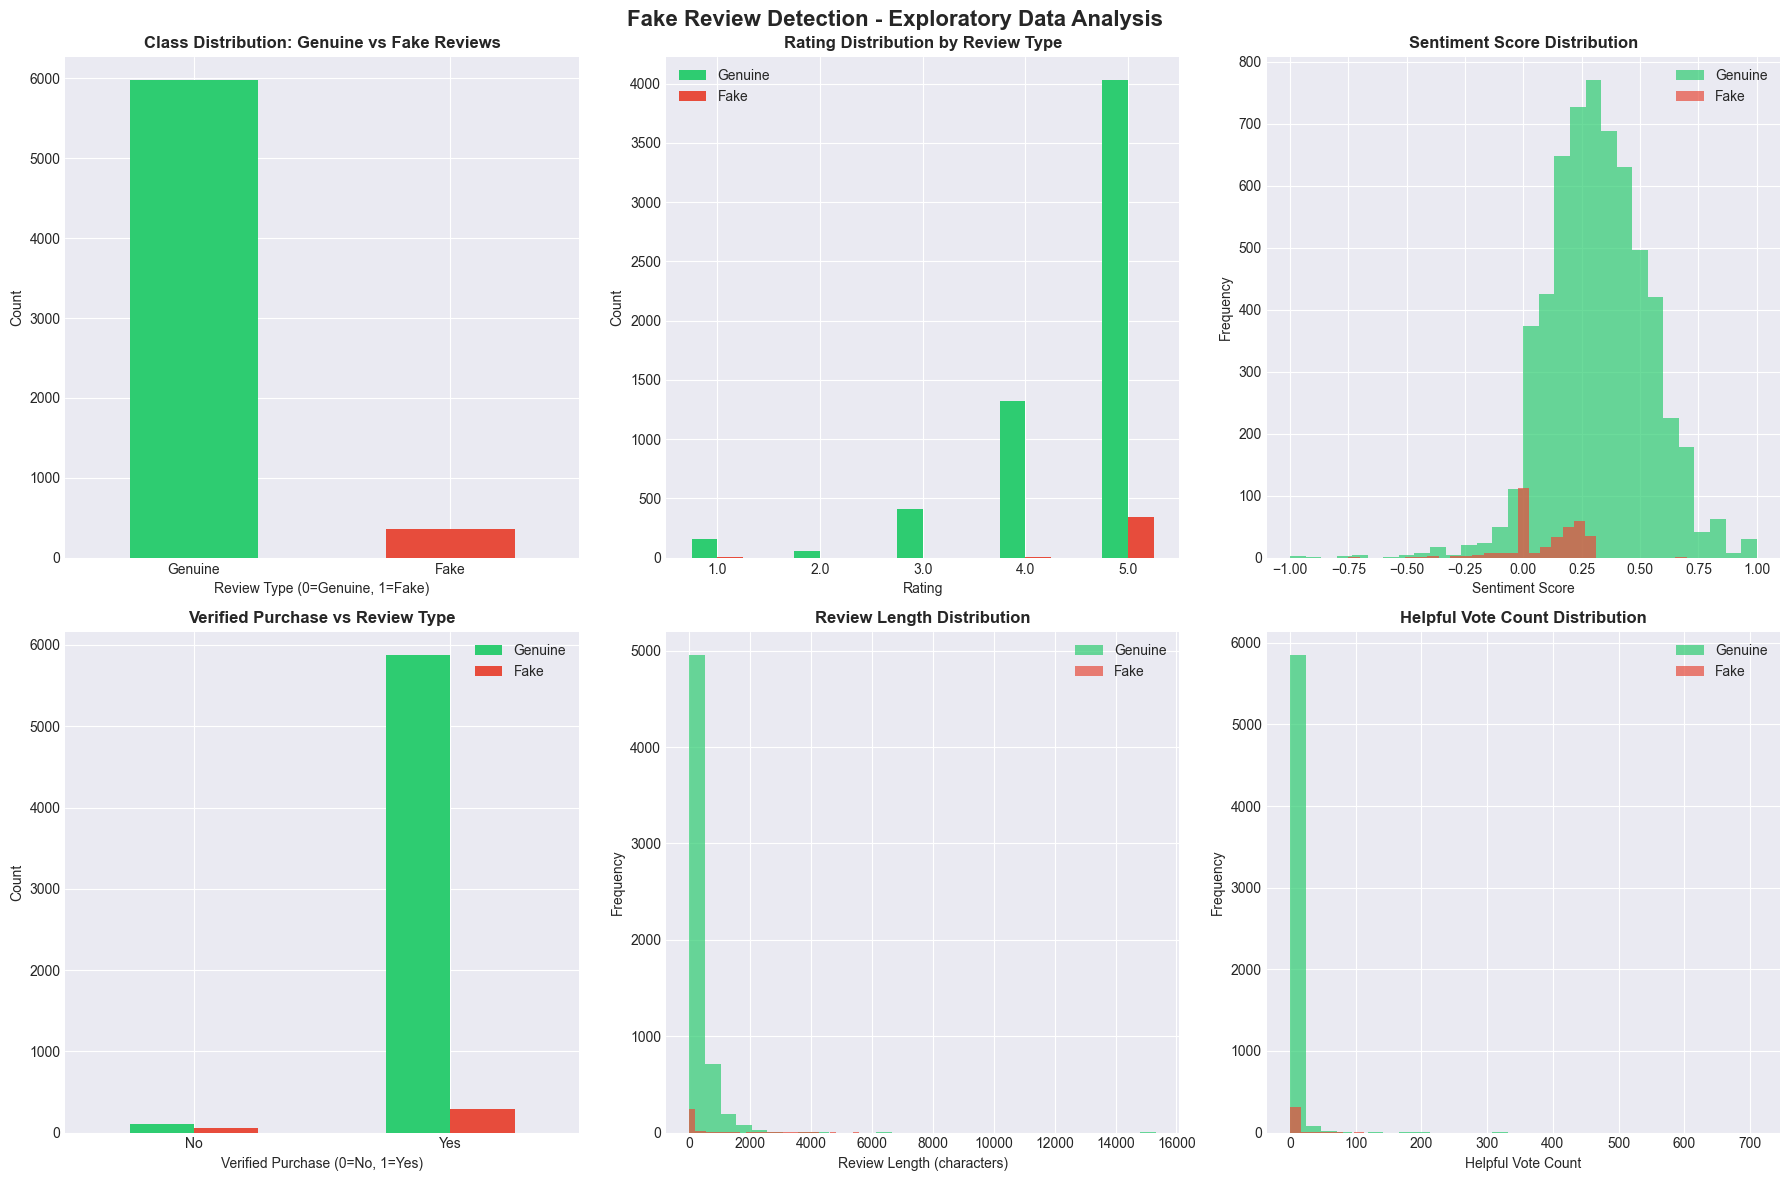

✓ Exploratory Data Analysis visualization saved as 'eda_visualization.png'


In [24]:
# Set up the figure
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
fig.suptitle('Fake Review Detection - Exploratory Data Analysis', fontsize=16, fontweight='bold')

# 1. Class Distribution
ax1 = axes[0, 0]
data['is_fake'].value_counts().plot(kind='bar', ax=ax1, color=['#2ecc71', '#e74c3c'])
ax1.set_title('Class Distribution: Genuine vs Fake Reviews', fontweight='bold')
ax1.set_xlabel('Review Type (0=Genuine, 1=Fake)')
ax1.set_ylabel('Count')
ax1.set_xticklabels(['Genuine', 'Fake'], rotation=0)

# 2. Rating Distribution by Review Type
ax2 = axes[0, 1]
data.groupby(['rating', 'is_fake']).size().unstack().plot(kind='bar', ax=ax2, color=['#2ecc71', '#e74c3c'])
ax2.set_title('Rating Distribution by Review Type', fontweight='bold')
ax2.set_xlabel('Rating')
ax2.set_ylabel('Count')
ax2.legend(['Genuine', 'Fake'])
ax2.set_xticklabels(ax2.get_xticklabels(), rotation=0)

# 3. Sentiment Score Distribution
ax3 = axes[0, 2]
data[data['is_fake']==0]['sentiment_score'].hist(bins=30, alpha=0.7, label='Genuine', color='#2ecc71', ax=ax3)
data[data['is_fake']==1]['sentiment_score'].hist(bins=30, alpha=0.7, label='Fake', color='#e74c3c', ax=ax3)
ax3.set_title('Sentiment Score Distribution', fontweight='bold')
ax3.set_xlabel('Sentiment Score')
ax3.set_ylabel('Frequency')
ax3.legend()

# 4. Verified Purchase Distribution
ax4 = axes[1, 0]
verified_fake = pd.crosstab(data['verifiedPurchase'], data['is_fake'])
verified_fake.plot(kind='bar', ax=ax4, color=['#2ecc71', '#e74c3c'])
ax4.set_title('Verified Purchase vs Review Type', fontweight='bold')
ax4.set_xlabel('Verified Purchase (0=No, 1=Yes)')
ax4.set_ylabel('Count')
ax4.legend(['Genuine', 'Fake'])
ax4.set_xticklabels(['No', 'Yes'], rotation=0)

# 5. Review Length Distribution
ax5 = axes[1, 1]
data[data['is_fake']==0]['review_length'].hist(bins=30, alpha=0.7, label='Genuine', color='#2ecc71', ax=ax5)
data[data['is_fake']==1]['review_length'].hist(bins=30, alpha=0.7, label='Fake', color='#e74c3c', ax=ax5)
ax5.set_title('Review Length Distribution', fontweight='bold')
ax5.set_xlabel('Review Length (characters)')
ax5.set_ylabel('Frequency')
ax5.legend()

# 6. Helpful Vote Count Distribution
ax6 = axes[1, 2]
data[data['is_fake']==0]['helpfulVoteCount'].hist(bins=30, alpha=0.7, label='Genuine', color='#2ecc71', ax=ax6)
data[data['is_fake']==1]['helpfulVoteCount'].hist(bins=30, alpha=0.7, label='Fake', color='#e74c3c', ax=ax6)
ax6.set_title('Helpful Vote Count Distribution', fontweight='bold')
ax6.set_xlabel('Helpful Vote Count')
ax6.set_ylabel('Frequency')
ax6.legend()

plt.tight_layout()
plt.savefig('eda_visualization.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Exploratory Data Analysis visualization saved as 'eda_visualization.png'")

## 5. Feature Correlation Analysis

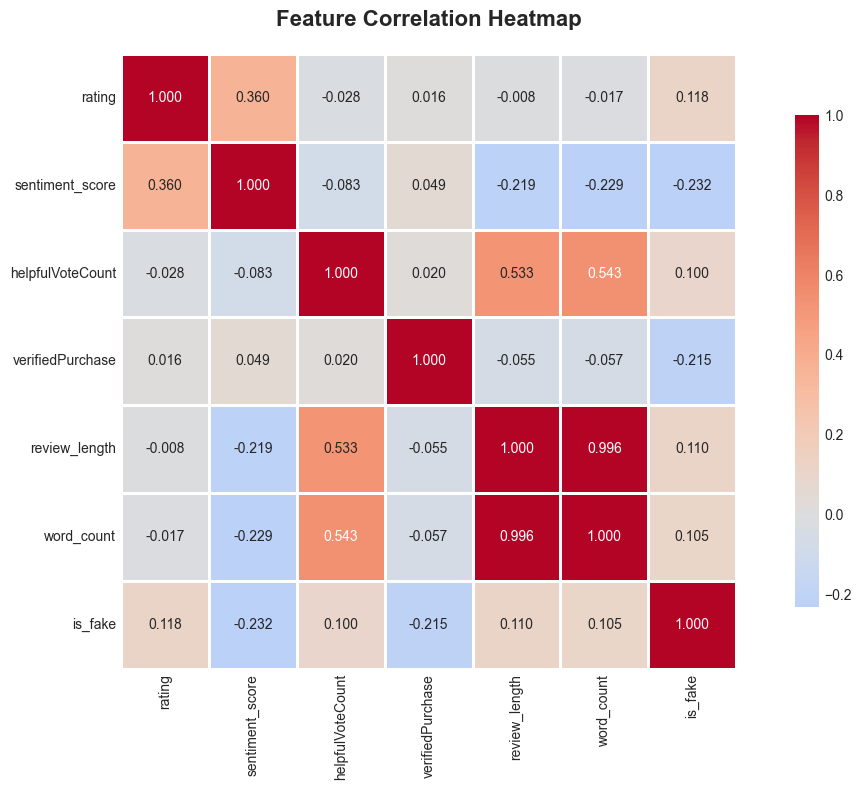

✓ Correlation heatmap saved as 'correlation_heatmap.png'

Top correlations with 'is_fake':
is_fake             1.000000
rating              0.118020
review_length       0.109608
word_count          0.105027
helpfulVoteCount    0.100006
verifiedPurchase   -0.215241
sentiment_score    -0.232409
Name: is_fake, dtype: float64


In [25]:
# Select numerical features for correlation analysis
correlation_features = ['rating', 'sentiment_score', 'helpfulVoteCount', 
                       'verifiedPurchase', 'review_length', 'word_count', 'is_fake']

correlation_matrix = data[correlation_features].corr()

# Plot correlation heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0, 
            square=True, linewidths=1, cbar_kws={"shrink": 0.8}, fmt='.3f')
plt.title('Feature Correlation Heatmap', fontsize=16, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig('correlation_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Correlation heatmap saved as 'correlation_heatmap.png'")
print("\nTop correlations with 'is_fake':")
print(correlation_matrix['is_fake'].sort_values(ascending=False))

## 6. Prepare Data for Training

In [26]:
# Select features for training
feature_columns = ['rating', 'sentiment_score', 'helpfulVoteCount', 
                   'verifiedPurchase', 'review_length', 'word_count']

X = data[feature_columns].copy()
y = data['is_fake'].copy()

# Handle any remaining NaN values comprehensively
print("Checking for NaN values before training...")
print("="*80)
print("NaN count per feature:")
print(X.isnull().sum())
print()

# Fill NaN values with appropriate strategies
X['rating'] = X['rating'].fillna(X['rating'].median())
X['sentiment_score'] = X['sentiment_score'].fillna(X['sentiment_score'].mean())
X['helpfulVoteCount'] = X['helpfulVoteCount'].fillna(0)
X['verifiedPurchase'] = X['verifiedPurchase'].fillna(0)
X['review_length'] = X['review_length'].fillna(0)
X['word_count'] = X['word_count'].fillna(0)

# Verify no NaN values remain
print("After filling NaN values:")
print(X.isnull().sum())
print()

# Replace any infinite values with 0
X = X.replace([np.inf, -np.inf], 0)

print("✓ All NaN and infinite values handled!")
print("="*80)

# Split the data: 70% train, 15% validation, 15% test
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.15, random_state=RANDOM_STATE, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.176, random_state=RANDOM_STATE, stratify=y_temp)

# Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# Final check for NaN values in scaled data
print("\nFinal verification - NaN count in scaled data:")
print(f"Training set: {np.isnan(X_train_scaled).sum()}")
print(f"Validation set: {np.isnan(X_val_scaled).sum()}")
print(f"Test set: {np.isnan(X_test_scaled).sum()}")

print("\nData Preparation Complete!")
print("\n" + "="*80)
print(f"Training Set: {X_train.shape[0]} samples ({X_train.shape[0]/len(X)*100:.1f}%)")
print(f"Validation Set: {X_val.shape[0]} samples ({X_val.shape[0]/len(X)*100:.1f}%)")
print(f"Test Set: {X_test.shape[0]} samples ({X_test.shape[0]/len(X)*100:.1f}%)")
print("\n" + "="*80)
print("Features used for training:")
for i, feature in enumerate(feature_columns, 1):
    print(f"{i}. {feature}")
print("\n" + "="*80)
print("Class distribution in training set:")
print(y_train.value_counts())
print("\nClass distribution in test set:")
print(y_test.value_counts())


Checking for NaN values before training...
NaN count per feature:
rating              0
sentiment_score     0
helpfulVoteCount    0
verifiedPurchase    0
review_length       0
word_count          0
dtype: int64

After filling NaN values:
rating              0
sentiment_score     0
helpfulVoteCount    0
verifiedPurchase    0
review_length       0
word_count          0
dtype: int64

✓ All NaN and infinite values handled!

Final verification - NaN count in scaled data:
Training set: 0
Validation set: 0
Test set: 0

Data Preparation Complete!

Training Set: 4430 samples (70.0%)
Validation Set: 947 samples (15.0%)
Test Set: 950 samples (15.0%)

Features used for training:
1. rating
2. sentiment_score
3. helpfulVoteCount
4. verifiedPurchase
5. review_length
6. word_count

Class distribution in training set:
0    4183
1     247
Name: is_fake, dtype: int64

Class distribution in test set:
0    897
1     53
Name: is_fake, dtype: int64


## 7. Model Training - Random Forest

In [27]:
print("Training Random Forest Classifier...")
print("="*80)

# Initialize Random Forest
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    class_weight='balanced'
)

# Train the model
rf_model.fit(X_train_scaled, y_train)

# Predictions
y_train_pred_rf = rf_model.predict(X_train_scaled)
y_val_pred_rf = rf_model.predict(X_val_scaled)
y_test_pred_rf = rf_model.predict(X_test_scaled)

# Prediction probabilities
y_train_proba_rf = rf_model.predict_proba(X_train_scaled)[:, 1]
y_val_proba_rf = rf_model.predict_proba(X_val_scaled)[:, 1]
y_test_proba_rf = rf_model.predict_proba(X_test_scaled)[:, 1]

# Evaluate
print("Random Forest Results:")
print("\nTraining Set Performance:")
print(f"Accuracy: {accuracy_score(y_train, y_train_pred_rf):.4f}")
print(f"Precision: {precision_score(y_train, y_train_pred_rf):.4f}")
print(f"Recall: {recall_score(y_train, y_train_pred_rf):.4f}")
print(f"F1-Score: {f1_score(y_train, y_train_pred_rf):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_train, y_train_proba_rf):.4f}")

print("\nValidation Set Performance:")
print(f"Accuracy: {accuracy_score(y_val, y_val_pred_rf):.4f}")
print(f"Precision: {precision_score(y_val, y_val_pred_rf):.4f}")
print(f"Recall: {recall_score(y_val, y_val_pred_rf):.4f}")
print(f"F1-Score: {f1_score(y_val, y_val_pred_rf):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_val, y_val_proba_rf):.4f}")

print("\nTest Set Performance:")
print(f"Accuracy: {accuracy_score(y_test, y_test_pred_rf):.4f}")
print(f"Precision: {precision_score(y_test, y_test_pred_rf):.4f}")
print(f"Recall: {recall_score(y_test, y_test_pred_rf):.4f}")
print(f"F1-Score: {f1_score(y_test, y_test_pred_rf):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, y_test_proba_rf):.4f}")

print("\n" + "="*80)
print("Classification Report (Test Set):")
print(classification_report(y_test, y_test_pred_rf, target_names=['Genuine', 'Fake']))

print("✓ Random Forest training completed!")

Training Random Forest Classifier...
Random Forest Results:

Training Set Performance:
Accuracy: 0.9995
Precision: 0.9920
Recall: 1.0000
F1-Score: 0.9960
ROC-AUC: 1.0000

Validation Set Performance:
Accuracy: 0.9968
Precision: 0.9808
Recall: 0.9623
F1-Score: 0.9714
ROC-AUC: 0.9999

Test Set Performance:
Accuracy: 0.9968
Precision: 0.9808
Recall: 0.9623
F1-Score: 0.9714
ROC-AUC: 0.9993

Classification Report (Test Set):
              precision    recall  f1-score   support

     Genuine       1.00      1.00      1.00       897
        Fake       0.98      0.96      0.97        53

    accuracy                           1.00       950
   macro avg       0.99      0.98      0.98       950
weighted avg       1.00      1.00      1.00       950

✓ Random Forest training completed!


## 8. Model Training - XGBoost

In [28]:
print("Training XGBoost Classifier...")
print("="*80)

# Calculate scale_pos_weight for imbalanced data
scale_pos_weight = len(y_train[y_train==0]) / len(y_train[y_train==1])

# Initialize XGBoost
xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    random_state=RANDOM_STATE,
    eval_metric='logloss',
    use_label_encoder=False
)

# Train the model
xgb_model.fit(X_train_scaled, y_train, 
              eval_set=[(X_val_scaled, y_val)], 
              verbose=False)

# Predictions
y_train_pred_xgb = xgb_model.predict(X_train_scaled)
y_val_pred_xgb = xgb_model.predict(X_val_scaled)
y_test_pred_xgb = xgb_model.predict(X_test_scaled)

# Prediction probabilities
y_train_proba_xgb = xgb_model.predict_proba(X_train_scaled)[:, 1]
y_val_proba_xgb = xgb_model.predict_proba(X_val_scaled)[:, 1]
y_test_proba_xgb = xgb_model.predict_proba(X_test_scaled)[:, 1]

# Evaluate
print("XGBoost Results:")
print("\nTraining Set Performance:")
print(f"Accuracy: {accuracy_score(y_train, y_train_pred_xgb):.4f}")
print(f"Precision: {precision_score(y_train, y_train_pred_xgb):.4f}")
print(f"Recall: {recall_score(y_train, y_train_pred_xgb):.4f}")
print(f"F1-Score: {f1_score(y_train, y_train_pred_xgb):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_train, y_train_proba_xgb):.4f}")

print("\nValidation Set Performance:")
print(f"Accuracy: {accuracy_score(y_val, y_val_pred_xgb):.4f}")
print(f"Precision: {precision_score(y_val, y_val_pred_xgb):.4f}")
print(f"Recall: {recall_score(y_val, y_val_pred_xgb):.4f}")
print(f"F1-Score: {f1_score(y_val, y_val_pred_xgb):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_val, y_val_proba_xgb):.4f}")

print("\nTest Set Performance:")
print(f"Accuracy: {accuracy_score(y_test, y_test_pred_xgb):.4f}")
print(f"Precision: {precision_score(y_test, y_test_pred_xgb):.4f}")
print(f"Recall: {recall_score(y_test, y_test_pred_xgb):.4f}")
print(f"F1-Score: {f1_score(y_test, y_test_pred_xgb):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, y_test_proba_xgb):.4f}")

print("\n" + "="*80)
print("Classification Report (Test Set):")
print(classification_report(y_test, y_test_pred_xgb, target_names=['Genuine', 'Fake']))

print("✓ XGBoost training completed!")

Training XGBoost Classifier...
XGBoost Results:

Training Set Performance:
Accuracy: 0.9995
Precision: 0.9920
Recall: 1.0000
F1-Score: 0.9960
ROC-AUC: 1.0000

Validation Set Performance:
Accuracy: 0.9979
Precision: 0.9811
Recall: 0.9811
F1-Score: 0.9811
ROC-AUC: 0.9999

Test Set Performance:
Accuracy: 0.9958
Precision: 0.9623
Recall: 0.9623
F1-Score: 0.9623
ROC-AUC: 0.9993

Classification Report (Test Set):
              precision    recall  f1-score   support

     Genuine       1.00      1.00      1.00       897
        Fake       0.96      0.96      0.96        53

    accuracy                           1.00       950
   macro avg       0.98      0.98      0.98       950
weighted avg       1.00      1.00      1.00       950

✓ XGBoost training completed!


## 9. Model Training - Logistic Regression

In [29]:
print("Training Logistic Regression Classifier...")
print("="*80)

# Initialize Logistic Regression
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=RANDOM_STATE,
    class_weight='balanced',
    solver='lbfgs'
)

# Train the model
lr_model.fit(X_train_scaled, y_train)

# Predictions
y_train_pred_lr = lr_model.predict(X_train_scaled)
y_val_pred_lr = lr_model.predict(X_val_scaled)
y_test_pred_lr = lr_model.predict(X_test_scaled)

# Prediction probabilities
y_train_proba_lr = lr_model.predict_proba(X_train_scaled)[:, 1]
y_val_proba_lr = lr_model.predict_proba(X_val_scaled)[:, 1]
y_test_proba_lr = lr_model.predict_proba(X_test_scaled)[:, 1]

# Evaluate
print("Logistic Regression Results:")
print("\nTraining Set Performance:")
print(f"Accuracy: {accuracy_score(y_train, y_train_pred_lr):.4f}")
print(f"Precision: {precision_score(y_train, y_train_pred_lr):.4f}")
print(f"Recall: {recall_score(y_train, y_train_pred_lr):.4f}")
print(f"F1-Score: {f1_score(y_train, y_train_pred_lr):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_train, y_train_proba_lr):.4f}")

print("\nValidation Set Performance:")
print(f"Accuracy: {accuracy_score(y_val, y_val_pred_lr):.4f}")
print(f"Precision: {precision_score(y_val, y_val_pred_lr):.4f}")
print(f"Recall: {recall_score(y_val, y_val_pred_lr):.4f}")
print(f"F1-Score: {f1_score(y_val, y_val_pred_lr):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_val, y_val_proba_lr):.4f}")

print("\nTest Set Performance:")
print(f"Accuracy: {accuracy_score(y_test, y_test_pred_lr):.4f}")
print(f"Precision: {precision_score(y_test, y_test_pred_lr):.4f}")
print(f"Recall: {recall_score(y_test, y_test_pred_lr):.4f}")
print(f"F1-Score: {f1_score(y_test, y_test_pred_lr):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, y_test_proba_lr):.4f}")

print("\n" + "="*80)
print("Classification Report (Test Set):")
print(classification_report(y_test, y_test_pred_lr, target_names=['Genuine', 'Fake']))

print("✓ Logistic Regression training completed!")

Training Logistic Regression Classifier...
Logistic Regression Results:

Training Set Performance:
Accuracy: 0.8361
Precision: 0.2318
Recall: 0.8381
F1-Score: 0.3632
ROC-AUC: 0.9292

Validation Set Performance:
Accuracy: 0.8300
Precision: 0.2216
Recall: 0.8113
F1-Score: 0.3482
ROC-AUC: 0.9322

Test Set Performance:
Accuracy: 0.8242
Precision: 0.2178
Recall: 0.8302
F1-Score: 0.3451
ROC-AUC: 0.9112

Classification Report (Test Set):
              precision    recall  f1-score   support

     Genuine       0.99      0.82      0.90       897
        Fake       0.22      0.83      0.35        53

    accuracy                           0.82       950
   macro avg       0.60      0.83      0.62       950
weighted avg       0.95      0.82      0.87       950

✓ Logistic Regression training completed!


## 10. Model Comparison Visualization


Model Comparison (Test Set):
                     Accuracy  Precision  Recall  F1-Score  ROC-AUC
Random Forest          0.9968     0.9808  0.9623    0.9714   0.9993
XGBoost                0.9958     0.9623  0.9623    0.9623   0.9993
Logistic Regression    0.8242     0.2178  0.8302    0.3451   0.9112


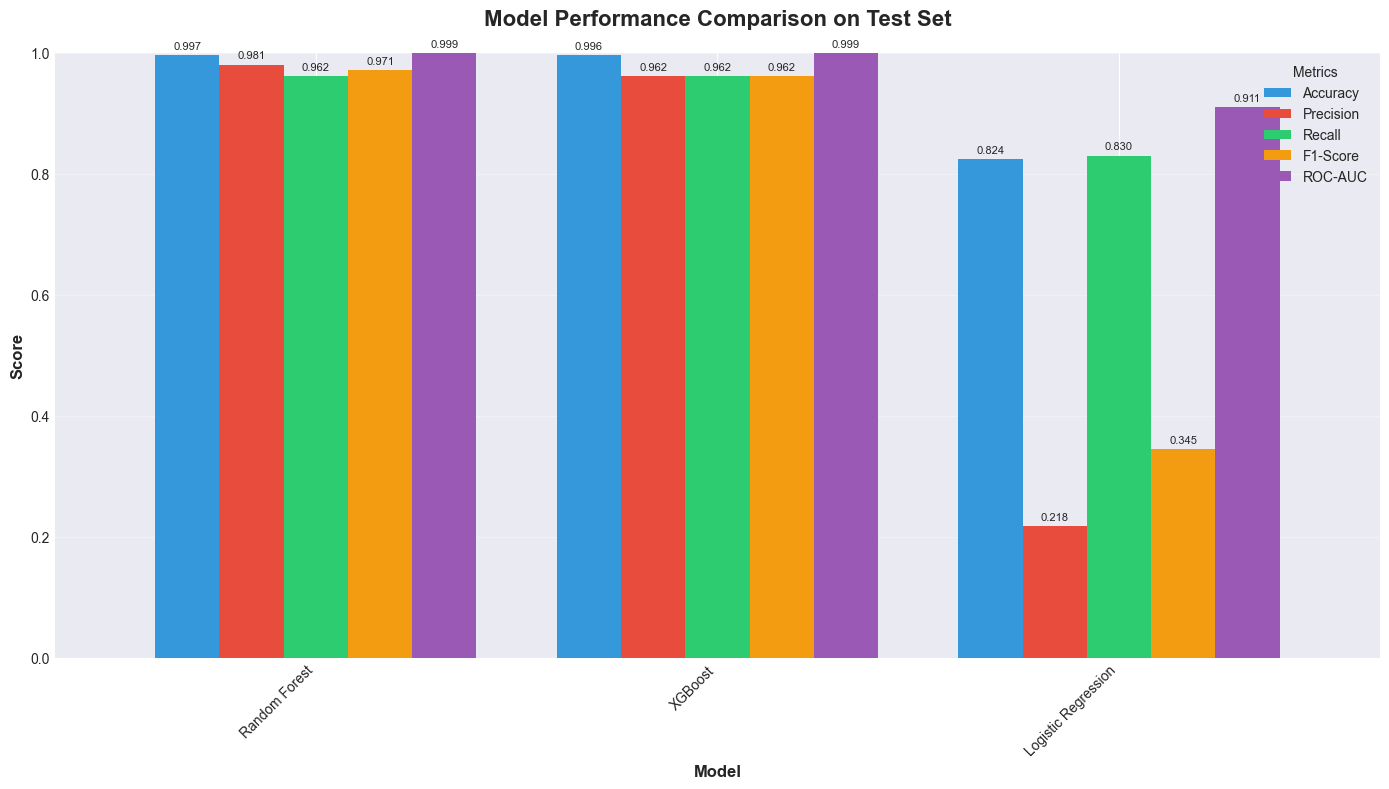


✓ Model comparison visualization saved as 'model_comparison.png'


In [30]:
# Compile results
models_results = {
    'Random Forest': {
        'Accuracy': accuracy_score(y_test, y_test_pred_rf),
        'Precision': precision_score(y_test, y_test_pred_rf),
        'Recall': recall_score(y_test, y_test_pred_rf),
        'F1-Score': f1_score(y_test, y_test_pred_rf),
        'ROC-AUC': roc_auc_score(y_test, y_test_proba_rf)
    },
    'XGBoost': {
        'Accuracy': accuracy_score(y_test, y_test_pred_xgb),
        'Precision': precision_score(y_test, y_test_pred_xgb),
        'Recall': recall_score(y_test, y_test_pred_xgb),
        'F1-Score': f1_score(y_test, y_test_pred_xgb),
        'ROC-AUC': roc_auc_score(y_test, y_test_proba_xgb)
    },
    'Logistic Regression': {
        'Accuracy': accuracy_score(y_test, y_test_pred_lr),
        'Precision': precision_score(y_test, y_test_pred_lr),
        'Recall': recall_score(y_test, y_test_pred_lr),
        'F1-Score': f1_score(y_test, y_test_pred_lr),
        'ROC-AUC': roc_auc_score(y_test, y_test_proba_lr)
    }
}

# Create comparison dataframe
results_df = pd.DataFrame(models_results).T
print("\nModel Comparison (Test Set):")
print("="*80)
print(results_df.round(4))

# Visualization: Bar plot comparison
fig, ax = plt.subplots(figsize=(14, 8))
results_df.plot(kind='bar', ax=ax, width=0.8, color=['#3498db', '#e74c3c', '#2ecc71', '#f39c12', '#9b59b6'])
ax.set_title('Model Performance Comparison on Test Set', fontsize=16, fontweight='bold', pad=20)
ax.set_xlabel('Model', fontsize=12, fontweight='bold')
ax.set_ylabel('Score', fontsize=12, fontweight='bold')
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
ax.legend(title='Metrics', fontsize=10)
ax.grid(axis='y', alpha=0.3)
ax.set_ylim([0, 1.0])

# Add value labels on bars
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=3, fontsize=8)

plt.tight_layout()
plt.savefig('model_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Model comparison visualization saved as 'model_comparison.png'")

## 11. Confusion Matrix Visualization

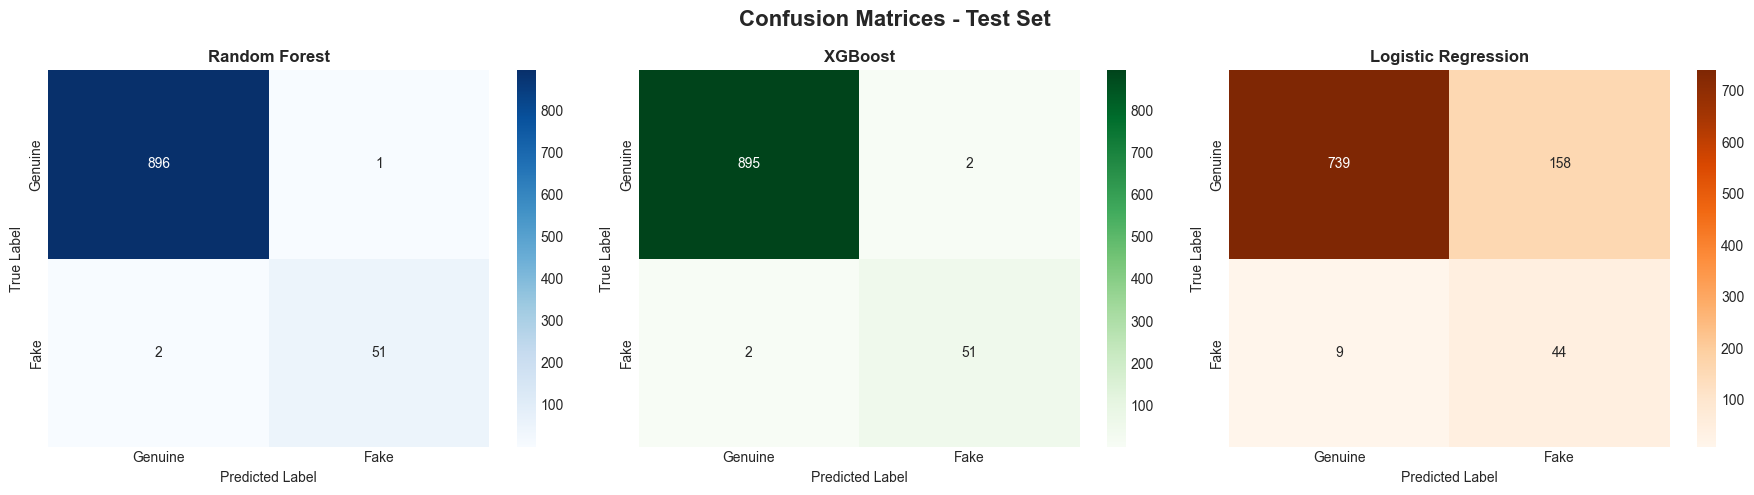

✓ Confusion matrices saved as 'confusion_matrices.png'


In [31]:
# Create confusion matrices
cm_rf = confusion_matrix(y_test, y_test_pred_rf)
cm_xgb = confusion_matrix(y_test, y_test_pred_xgb)
cm_lr = confusion_matrix(y_test, y_test_pred_lr)

# Plot confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Confusion Matrices - Test Set', fontsize=16, fontweight='bold')

# Random Forest
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues', ax=axes[0], 
            xticklabels=['Genuine', 'Fake'], yticklabels=['Genuine', 'Fake'])
axes[0].set_title('Random Forest', fontweight='bold')
axes[0].set_ylabel('True Label')
axes[0].set_xlabel('Predicted Label')

# XGBoost
sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=['Genuine', 'Fake'], yticklabels=['Genuine', 'Fake'])
axes[1].set_title('XGBoost', fontweight='bold')
axes[1].set_ylabel('True Label')
axes[1].set_xlabel('Predicted Label')

# Logistic Regression
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Oranges', ax=axes[2],
            xticklabels=['Genuine', 'Fake'], yticklabels=['Genuine', 'Fake'])
axes[2].set_title('Logistic Regression', fontweight='bold')
axes[2].set_ylabel('True Label')
axes[2].set_xlabel('Predicted Label')

plt.tight_layout()
plt.savefig('confusion_matrices.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Confusion matrices saved as 'confusion_matrices.png'")

## 12. ROC Curve and AUC Visualization

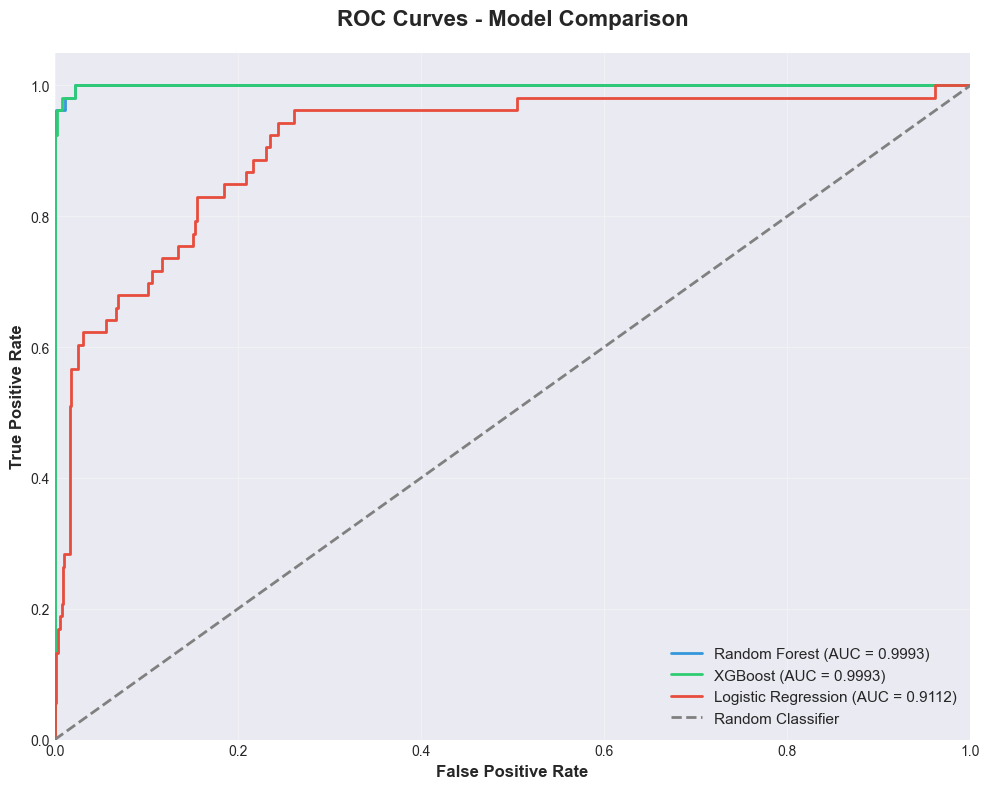

✓ ROC curves saved as 'roc_curves.png'


In [33]:
# Calculate ROC curves
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_test_proba_rf)
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_test_proba_xgb)
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_test_proba_lr)

roc_auc_rf = auc(fpr_rf, tpr_rf)
roc_auc_xgb = auc(fpr_xgb, tpr_xgb)
roc_auc_lr = auc(fpr_lr, tpr_lr)

# Plot ROC curves
plt.figure(figsize=(10, 8))
plt.plot(fpr_rf, tpr_rf, color='#3498db', lw=2, label=f'Random Forest (AUC = {roc_auc_rf:.4f})')
plt.plot(fpr_xgb, tpr_xgb, color='#2ecc71', lw=2, label=f'XGBoost (AUC = {roc_auc_xgb:.4f})')
plt.plot(fpr_lr, tpr_lr, color='#e74c3c', lw=2, label=f'Logistic Regression (AUC = {roc_auc_lr:.4f})')
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--', label='Random Classifier')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12, fontweight='bold')
plt.ylabel('True Positive Rate', fontsize=12, fontweight='bold')
plt.title('ROC Curves - Model Comparison', fontsize=16, fontweight='bold', pad=20)
plt.legend(loc="lower right", fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('roc_curves.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ ROC curves saved as 'roc_curves.png'")

## 13. Precision-Recall Curve Visualization

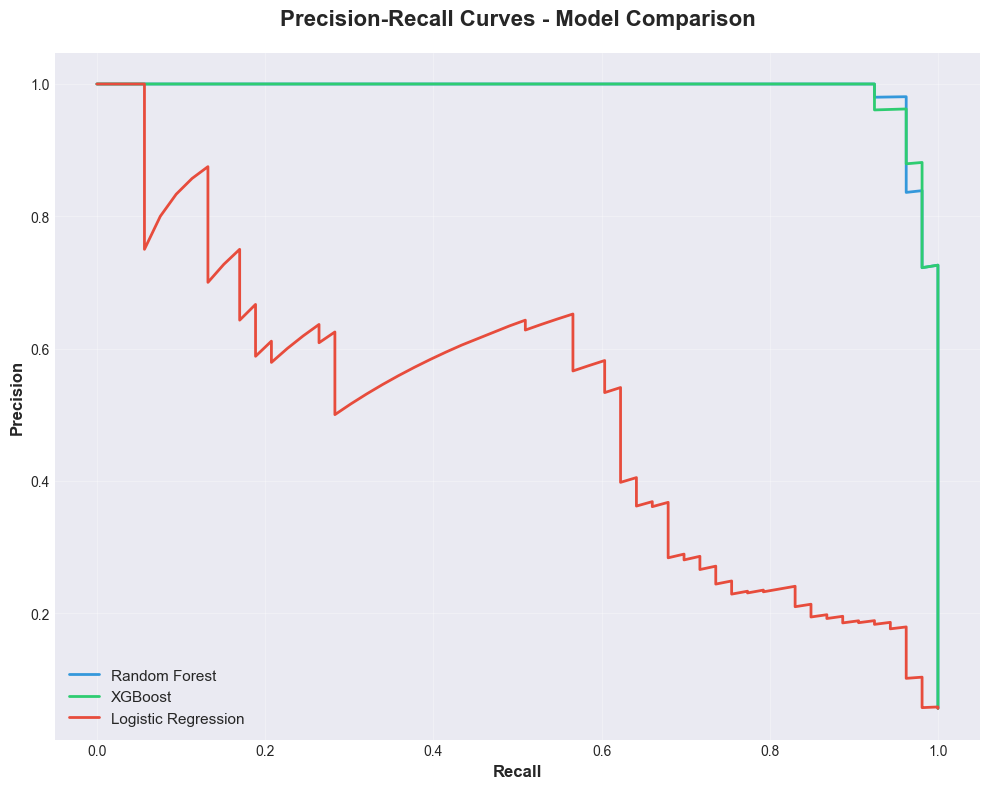

✓ Precision-Recall curves saved as 'precision_recall_curves.png'


In [34]:
# Calculate Precision-Recall curves
precision_rf, recall_rf, _ = precision_recall_curve(y_test, y_test_proba_rf)
precision_xgb, recall_xgb, _ = precision_recall_curve(y_test, y_test_proba_xgb)
precision_lr, recall_lr, _ = precision_recall_curve(y_test, y_test_proba_lr)

# Plot Precision-Recall curves
plt.figure(figsize=(10, 8))
plt.plot(recall_rf, precision_rf, color='#3498db', lw=2, label='Random Forest')
plt.plot(recall_xgb, precision_xgb, color='#2ecc71', lw=2, label='XGBoost')
plt.plot(recall_lr, precision_lr, color='#e74c3c', lw=2, label='Logistic Regression')

plt.xlabel('Recall', fontsize=12, fontweight='bold')
plt.ylabel('Precision', fontsize=12, fontweight='bold')
plt.title('Precision-Recall Curves - Model Comparison', fontsize=16, fontweight='bold', pad=20)
plt.legend(loc="best", fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('precision_recall_curves.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Precision-Recall curves saved as 'precision_recall_curves.png'")

## 14. Feature Importance Analysis

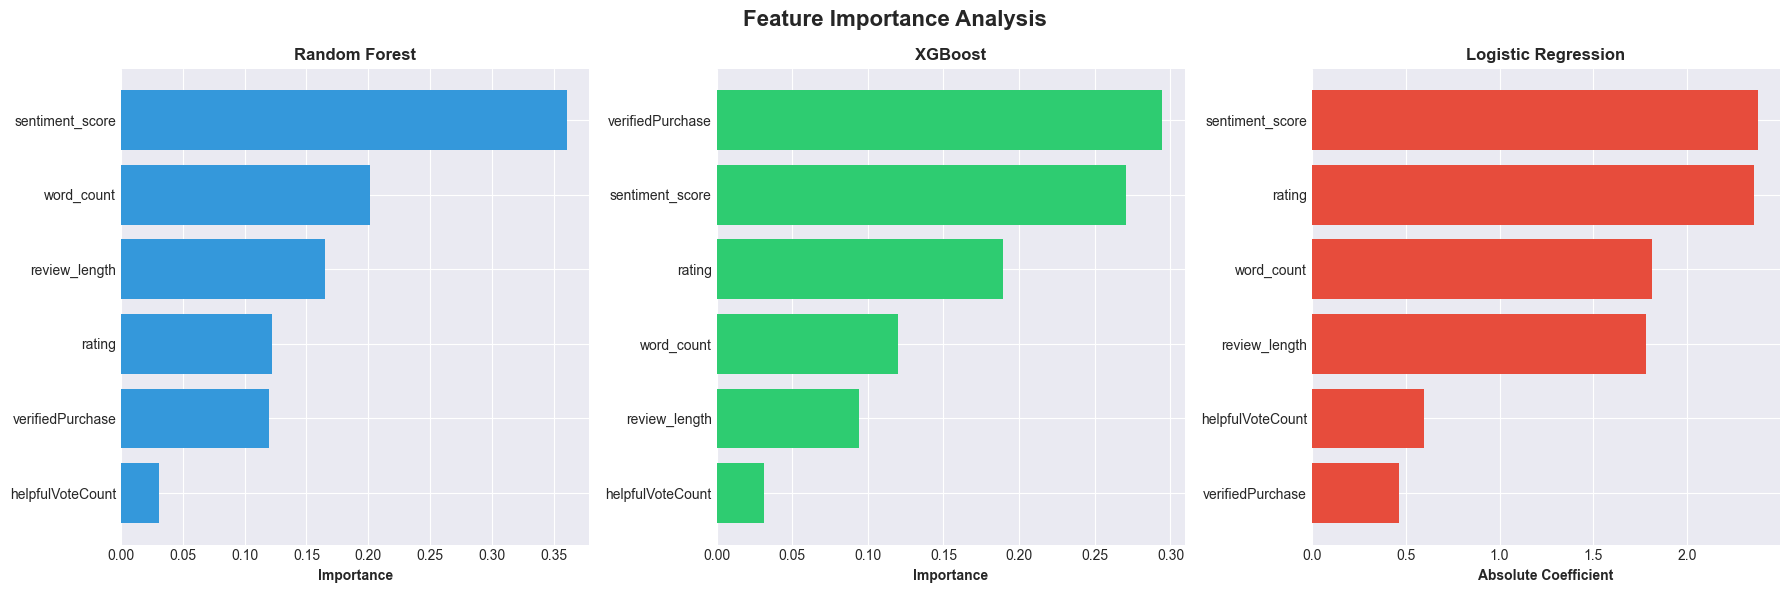


Random Forest - Top Features:
            Feature  Importance
1   sentiment_score    0.360803
5        word_count    0.201417
4     review_length    0.165007
0            rating    0.122450
3  verifiedPurchase    0.119427
2  helpfulVoteCount    0.030896

XGBoost - Top Features:
            Feature  Importance
3  verifiedPurchase    0.294612
1   sentiment_score    0.270669
0            rating    0.189584
5        word_count    0.119805
4     review_length    0.093882
2  helpfulVoteCount    0.031447

Logistic Regression - Top Features:
            Feature  Coefficient
1   sentiment_score     2.374976
0            rating     2.355026
5        word_count     1.810642
4     review_length     1.782034
2  helpfulVoteCount     0.595597
3  verifiedPurchase     0.463545

✓ Feature importance analysis saved as 'feature_importance.png'


In [35]:
# Get feature importance from tree-based models
rf_importance = pd.DataFrame({
    'Feature': feature_columns,
    'Importance': rf_model.feature_importances_
}).sort_values('Importance', ascending=False)

xgb_importance = pd.DataFrame({
    'Feature': feature_columns,
    'Importance': xgb_model.feature_importances_
}).sort_values('Importance', ascending=False)

# Get coefficients from Logistic Regression
lr_coefficients = pd.DataFrame({
    'Feature': feature_columns,
    'Coefficient': np.abs(lr_model.coef_[0])
}).sort_values('Coefficient', ascending=False)

# Plot feature importance
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('Feature Importance Analysis', fontsize=16, fontweight='bold')

# Random Forest
axes[0].barh(rf_importance['Feature'], rf_importance['Importance'], color='#3498db')
axes[0].set_xlabel('Importance', fontweight='bold')
axes[0].set_title('Random Forest', fontweight='bold')
axes[0].invert_yaxis()

# XGBoost
axes[1].barh(xgb_importance['Feature'], xgb_importance['Importance'], color='#2ecc71')
axes[1].set_xlabel('Importance', fontweight='bold')
axes[1].set_title('XGBoost', fontweight='bold')
axes[1].invert_yaxis()

# Logistic Regression
axes[2].barh(lr_coefficients['Feature'], lr_coefficients['Coefficient'], color='#e74c3c')
axes[2].set_xlabel('Absolute Coefficient', fontweight='bold')
axes[2].set_title('Logistic Regression', fontweight='bold')
axes[2].invert_yaxis()

plt.tight_layout()
plt.savefig('feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()

print("\nRandom Forest - Top Features:")
print(rf_importance)
print("\nXGBoost - Top Features:")
print(xgb_importance)
print("\nLogistic Regression - Top Features:")
print(lr_coefficients)

print("\n✓ Feature importance analysis saved as 'feature_importance.png'")

## 15. Save Models and Scaler

In [36]:
import os

# Create models directory
os.makedirs('models', exist_ok=True)

# Save Random Forest model
joblib.dump(rf_model, 'models/random_forest_model.pkl')
print("✓ Random Forest model saved as 'models/random_forest_model.pkl'")

# Save XGBoost model
joblib.dump(xgb_model, 'models/xgboost_model.pkl')
print("✓ XGBoost model saved as 'models/xgboost_model.pkl'")

# Save Logistic Regression model
joblib.dump(lr_model, 'models/logistic_regression_model.pkl')
print("✓ Logistic Regression model saved as 'models/logistic_regression_model.pkl'")

# Save the scaler
joblib.dump(scaler, 'models/scaler.pkl')
print("✓ Feature scaler saved as 'models/scaler.pkl'")

# Save feature names
with open('models/feature_names.pkl', 'wb') as f:
    pickle.dump(feature_columns, f)
print("✓ Feature names saved as 'models/feature_names.pkl'")

# Save model performance metrics
results_df.to_csv('models/model_performance.csv')
print("✓ Model performance metrics saved as 'models/model_performance.csv'")

print("\n" + "="*80)
print("All models and artifacts saved successfully!")
print("="*80)

✓ Random Forest model saved as 'models/random_forest_model.pkl'
✓ XGBoost model saved as 'models/xgboost_model.pkl'
✓ Logistic Regression model saved as 'models/logistic_regression_model.pkl'
✓ Feature scaler saved as 'models/scaler.pkl'
✓ Feature names saved as 'models/feature_names.pkl'
✓ Model performance metrics saved as 'models/model_performance.csv'

All models and artifacts saved successfully!


## 16. Test Model Loading and Prediction

In [37]:
# Load the best performing model
print("Testing model loading and prediction...")
print("="*80)

# Load models
loaded_rf = joblib.load('models/random_forest_model.pkl')
loaded_xgb = joblib.load('models/xgboost_model.pkl')
loaded_lr = joblib.load('models/logistic_regression_model.pkl')
loaded_scaler = joblib.load('models/scaler.pkl')

print("✓ Models loaded successfully!")

# Test prediction on samples - OPTIMIZED (batch prediction)
sample_reviews = X_test.iloc[0:5]
sample_reviews_scaled = loaded_scaler.transform(sample_reviews)

# Batch predictions (much faster)
rf_preds = loaded_rf.predict(sample_reviews_scaled)
rf_probas = loaded_rf.predict_proba(sample_reviews_scaled)[:, 1]

xgb_preds = loaded_xgb.predict(sample_reviews_scaled)
xgb_probas = loaded_xgb.predict_proba(sample_reviews_scaled)[:, 1]

lr_preds = loaded_lr.predict(sample_reviews_scaled)
lr_probas = loaded_lr.predict_proba(sample_reviews_scaled)[:, 1]

print("\nTest Predictions on 5 Sample Reviews:")
print("="*80)

for i in range(5):
    row = sample_reviews.iloc[i]
    print(f"\nSample {i+1}:")
    print(f"Features: Rating={row['rating']:.0f}, Sentiment={row['sentiment_score']:.3f}, "
          f"Verified={row['verifiedPurchase']:.0f}, WordCount={row['word_count']:.0f}")
    print(f"True Label: {'Fake' if y_test.iloc[i] == 1 else 'Genuine'}")
    print(f"Random Forest: {'Fake' if rf_preds[i] == 1 else 'Genuine'} (Prob: {rf_probas[i]:.3f})")
    print(f"XGBoost: {'Fake' if xgb_preds[i] == 1 else 'Genuine'} (Prob: {xgb_probas[i]:.3f})")
    print(f"Logistic Regression: {'Fake' if lr_preds[i] == 1 else 'Genuine'} (Prob: {lr_probas[i]:.3f})")

print("\n" + "="*80)
print("Model testing completed successfully!")


Testing model loading and prediction...
✓ Models loaded successfully!

Test Predictions on 5 Sample Reviews:

Sample 1:
Features: Rating=4, Sentiment=0.300, Verified=1, WordCount=53
True Label: Genuine
Random Forest: Genuine (Prob: 0.000)
XGBoost: Genuine (Prob: 0.000)
Logistic Regression: Genuine (Prob: 0.025)

Sample 2:
Features: Rating=5, Sentiment=0.325, Verified=1, WordCount=9
True Label: Genuine
Random Forest: Genuine (Prob: 0.016)
XGBoost: Genuine (Prob: 0.001)
Logistic Regression: Genuine (Prob: 0.234)

Sample 3:
Features: Rating=5, Sentiment=0.147, Verified=1, WordCount=100
True Label: Genuine
Random Forest: Genuine (Prob: 0.000)
XGBoost: Genuine (Prob: 0.000)
Logistic Regression: Fake (Prob: 0.690)

Sample 4:
Features: Rating=5, Sentiment=0.333, Verified=1, WordCount=27
True Label: Genuine
Random Forest: Genuine (Prob: 0.000)
XGBoost: Genuine (Prob: 0.000)
Logistic Regression: Genuine (Prob: 0.216)

Sample 5:
Features: Rating=4, Sentiment=0.371, Verified=1, WordCount=50
True 

## 17. Summary and Recommendations

In [38]:
print("\n" + "="*80)
print("FAKE REVIEW DETECTION MODEL - TRAINING SUMMARY")
print("="*80)

print("\n1. DATASET INFORMATION:")
print(f"   - Total Reviews: {len(data)}")
print(f"   - Genuine Reviews: {len(data[data['is_fake']==0])} ({len(data[data['is_fake']==0])/len(data)*100:.1f}%)")
print(f"   - Fake Reviews: {len(data[data['is_fake']==1])} ({len(data[data['is_fake']==1])/len(data)*100:.1f}%)")

print("\n2. FEATURES USED:")
for i, feature in enumerate(feature_columns, 1):
    print(f"   {i}. {feature}")

print("\n3. MODEL PERFORMANCE SUMMARY (Test Set):")
print(results_df.round(4).to_string())

# Determine best model
best_model_name = results_df['F1-Score'].idxmax()
best_f1_score = results_df['F1-Score'].max()

print(f"\n4. BEST PERFORMING MODEL:")
print(f"   - Model: {best_model_name}")
print(f"   - F1-Score: {best_f1_score:.4f}")
print(f"   - Accuracy: {results_df.loc[best_model_name, 'Accuracy']:.4f}")
print(f"   - ROC-AUC: {results_df.loc[best_model_name, 'ROC-AUC']:.4f}")

print("\n5. FILES GENERATED:")
print("   Visualizations:")
print("   - eda_visualization.png")
print("   - correlation_heatmap.png")
print("   - model_comparison.png")
print("   - confusion_matrices.png")
print("   - roc_curves.png")
print("   - precision_recall_curves.png")
print("   - feature_importance.png")
print("\n   Models:")
print("   - models/random_forest_model.pkl")
print("   - models/xgboost_model.pkl")
print("   - models/logistic_regression_model.pkl")
print("   - models/scaler.pkl")
print("   - models/feature_names.pkl")
print("   - models/model_performance.csv")

print("\n6. RECOMMENDATIONS:")
print("   - Use the saved models for deployment in production")
print("   - Implement probability threshold tuning for optimal precision-recall trade-off")
print("   - Consider ensemble methods combining multiple models for better performance")
print("   - Regularly retrain models with new data to maintain accuracy")
print("   - Monitor model performance and adjust fake detection rules as needed")

print("\n" + "="*80)
print("Training pipeline completed successfully!")
print("="*80)


FAKE REVIEW DETECTION MODEL - TRAINING SUMMARY

1. DATASET INFORMATION:
   - Total Reviews: 6327
   - Genuine Reviews: 5974 (94.4%)
   - Fake Reviews: 353 (5.6%)

2. FEATURES USED:
   1. rating
   2. sentiment_score
   3. helpfulVoteCount
   4. verifiedPurchase
   5. review_length
   6. word_count

3. MODEL PERFORMANCE SUMMARY (Test Set):
                     Accuracy  Precision  Recall  F1-Score  ROC-AUC
Random Forest          0.9968     0.9808  0.9623    0.9714   0.9993
XGBoost                0.9958     0.9623  0.9623    0.9623   0.9993
Logistic Regression    0.8242     0.2178  0.8302    0.3451   0.9112

4. BEST PERFORMING MODEL:
   - Model: Random Forest
   - F1-Score: 0.9714
   - Accuracy: 0.9968
   - ROC-AUC: 0.9993

5. FILES GENERATED:
   Visualizations:
   - eda_visualization.png
   - correlation_heatmap.png
   - model_comparison.png
   - confusion_matrices.png
   - roc_curves.png
   - precision_recall_curves.png
   - feature_importance.png

   Models:
   - models/random_forest